# Furnace_Tube_Data.csv 튜브 Furnace 시계열 데이터 분석 (원본)

1. 데이터 로드 및 기본 점검
2. 시간축 구조 (샘플링 주기, 공백, Run 구분)
3. Code_Num / Process_Type 구조
4. 센서 신호 특성 (자기상관 — 신호 vs 잡음)
5. 튜브 구역 온도 균일성
6. 제어 출력(OP / CP) 거동
7. 결측치 패턴
8. 시각화 & 결론

> 파생 컬럼(`이상치개수`, `정상여부`, `요일`)이 추가된 버전은 `Furnace_analysis.ipynb` 에서 다룹니다.

## 1. 데이터 로드 및 기본 점검

In [1]:
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

df = pd.read_csv('../data/Furnace_Tube_Data.csv')
df['dt'] = pd.to_datetime(df['Datetime'])

NUM = ['Z1_Temp', 'Z1_OP1', 'ST',
       'Tube_Furnace1_OP', 'Tube_Furnace2_OP', 'Tube_Furnace3_OP', 'Tube_Furnace4_OP', 'Tube_Furnace_CP',
       'Tube_Furnace1_Temp', 'Tube_Furnace2_Temp', 'Tube_Furnace3_Temp', 'Tube_Furnace4_Temp']
TEMPS = [f'Tube_Furnace{i}_Temp' for i in range(1, 5)]
OPS = [f'Tube_Furnace{i}_OP' for i in range(1, 5)]

print(f'데이터 크기: {df.shape[0]:,}행 × {df.shape[1] - 1}열 (dt 파싱 컬럼 제외)')
df.head()

데이터 크기: 231,123행 × 15열 (dt 파싱 컬럼 제외)


,Process_Type,Datetime,Code_Num,Z1_Temp,Z1_OP1,ST,Tube_Furnace1_OP,Tube_Furnace2_OP,Tube_Furnace3_OP,Tube_Furnace4_OP,Tube_Furnace_CP,Tube_Furnace1_Temp,Tube_Furnace2_Temp,Tube_Furnace3_Temp,Tube_Furnace4_Temp,dt
0,OP-A,2022-01-03 11:22,GroupA,NaN,75.6648,NaN,73.527404,59.989422,52.249481,72.134908,0.450497,NaN,868.759544,NaN,NaN,2022-01-03 11:22:00
1,OP-A,2022-01-03 11:22,GroupA,NaN,75.6706,NaN,79.149174,62.027232,50.617109,71.245235,0.457370,878.116929,883.821264,890.740760,894.430606,2022-01-03 11:22:00
2,OP-A,2022-01-03 11:22,GroupA,99.614201,75.6776,68.724636,78.946336,62.235532,52.218350,72.705558,0.454914,866.441979,882.850031,864.373065,893.530501,2022-01-03 11:22:00
3,OP-A,2022-01-03 11:22,GroupA,99.376221,75.8656,69.161116,78.445719,61.608260,52.863552,73.975640,0.456540,876.350472,906.208463,891.107865,896.347636,2022-01-03 11:22:00
4,OP-C,2022-01-03 11:22,GroupA,99.809053,73.6468,69.181098,76.673808,61.589311,52.297196,71.887865,0.460100,903.587678,867.215131,893.206883,871.594283,2022-01-03 11:22:00


In [2]:
na = df[NUM].isna().sum()
print(f'결측치 합계: {na.sum():,}셀 / 결측 포함 행: {df[NUM].isna().any(axis=1).sum():,}행')
print(f'중복 행    : {df.drop(columns="dt").duplicated().sum():,}')
print()
print(f'[컬럼별 결측치]')
for c, v in na[na > 0].items():
    print(f'  {c:<20s}: {v:>4,}개 ({v / len(df):.3%})')

결측치 합계: 343셀 / 결측 포함 행: 284행


중복 행    : 0

[컬럼별 결측치]
  Z1_Temp             :   25개 (0.011%)
  ST                  :   25개 (0.011%)
  Tube_Furnace1_OP    :  254개 (0.110%)
  Tube_Furnace1_Temp  :    5개 (0.002%)
  Tube_Furnace2_Temp  :   10개 (0.004%)
  Tube_Furnace3_Temp  :    9개 (0.004%)
  Tube_Furnace4_Temp  :   15개 (0.006%)


In [3]:
desc = df[NUM].describe().T
desc['count'] = desc['count'].astype(int)
desc['nunique'] = df[NUM].nunique()
desc['cv%'] = desc['std'] / desc['mean'] * 100

with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(desc)

,count,mean,std,min,25%,50%,75%,max,nunique,cv%
Z1_Temp,231098,100.5097,0.4272,98.3709,100.2340,100.5065,100.7794,102.6640,229233,0.4250
Z1_OP1,231123,72.6226,3.0091,52.9816,71.3191,72.9036,74.4050,84.5911,93274,4.1435
ST,231098,69.0930,1.0783,64.9914,68.2532,69.0847,69.9961,71.5270,231023,1.5606
Tube_Furnace1_OP,230869,75.3096,20.6631,0.0054,68.8801,78.7084,87.6979,101.0000,230834,27.4375
Tube_Furnace2_OP,231123,47.5720,4.4135,35.2017,45.2192,46.7344,48.4129,66.8253,231090,9.2775
Tube_Furnace3_OP,231123,50.5330,1.9651,37.5194,49.4197,50.6469,51.7991,59.4909,231098,3.8888
Tube_Furnace4_OP,231123,70.2475,2.2818,56.7485,68.8756,70.2691,71.5544,83.4108,231071,3.2482
Tube_Furnace_CP,231123,0.4497,0.0442,0.0980,0.4520,0.4549,0.4578,0.9163,229402,9.8246
Tube_Furnace1_Temp,231118,884.5382,14.6056,848.2845,872.0574,884.5274,896.9609,920.8327,231055,1.6512
Tube_Furnace2_Temp,231113,885.0415,14.4184,858.6697,872.5614,885.0474,897.5376,911.3588,231063,1.6291


## 2. 시간축 구조

In [4]:
ts = df['dt']
per_min = df.groupby('dt').size()
gaps = ts.drop_duplicates().diff().dropna()

print(f'기간         : {ts.min()} ~ {ts.max()}')
print(f'정렬 여부    : {ts.is_monotonic_increasing}')
print(f'고유 시각(분): {ts.nunique():,}개')
print(f'분당 행 수   : 평균 {per_min.mean():.1f} / 중앙값 {per_min.median():.0f} / 최대 {per_min.max()}')
print(f'→ 타임스탬프는 분 단위로 잘려 있고, 실제 샘플링은 약 1초 간격(분당 ~58행)으로 추정')
print()
print(f'연속 분 간격(1분): {(gaps == pd.Timedelta("1min")).sum():,}회 / 1시간 초과 공백: {(gaps > pd.Timedelta("1h")).sum()}회')

기간         : 2022-01-03 11:22:00 ~ 2022-01-15 19:49:00
정렬 여부    : True
고유 시각(분): 3,996개
분당 행 수   : 평균 57.8 / 중앙값 59 / 최대 60
→ 타임스탬프는 분 단위로 잘려 있고, 실제 샘플링은 약 1초 간격(분당 ~58행)으로 추정

연속 분 간격(1분): 3,985회 / 1시간 초과 공백: 10회


In [5]:
# Code_Num 이 바뀌는 지점 = Run(가동 구간) 경계 (공백과 정확히 일치)
df['run'] = (df['Code_Num'] != df['Code_Num'].shift()).cumsum()
runs = df.groupby('run').agg(Code_Num=('Code_Num', 'first'), start=('dt', 'min'), end=('dt', 'max'), rows=('dt', 'size'))
runs['minutes'] = ((runs['end'] - runs['start']).dt.total_seconds() / 60 + 1).astype(int)
runs['gap_before'] = (runs['start'] - runs['end'].shift()).astype(str).str.replace('0 days ', '')
print(f'Run 수: {len(runs)}개 (Code_Num 7종, GroupA~D 는 2회씩 반복)')
runs

Run 수: 11개 (Code_Num 7종, GroupA~D 는 2회씩 반복)


,Code_Num,start,end,rows,minutes,gap_before
run,,,,,,
1,GroupA,2022-01-03 11:22:00,2022-01-03 13:27:00,7342,126,NaN
2,GroupB,2022-01-03 22:35:00,2022-01-04 02:20:00,13299,226,09:08:00
3,GroupC,2022-01-04 22:34:00,2022-01-05 06:20:00,26982,467,20:14:00
4,GroupD,2022-01-05 14:32:00,2022-01-05 23:40:00,31729,549,08:12:00
5,GroupE,2022-01-06 22:29:00,2022-01-07 00:16:00,6218,108,22:49:00
6,GroupF,2022-01-07 04:07:00,2022-01-07 11:31:00,25708,445,03:51:00
7,GroupG,2022-01-08 04:43:00,2022-01-08 08:20:00,12559,218,17:12:00
8,GroupA,2022-01-10 11:17:00,2022-01-11 00:50:00,46836,814,2 days 02:57:00
9,GroupB,2022-01-12 13:09:00,2022-01-12 23:21:00,35348,613,1 days 12:19:00


## 3. Code_Num / Process_Type 구조

In [6]:
switches = (df['Process_Type'] != df['Process_Type'].shift()).sum()
print(f'Process_Type 분포: ' + ', '.join(f'{k} {v:,}행 ({v / len(df):.1%})' for k, v in df['Process_Type'].value_counts().items()))
print(f'Process_Type 전환 횟수: {switches:,}회 → 배치 단위가 아니라 행 단위로 섞여 있음')
print()
print(f'[Code_Num × Process_Type 행 수]')
print(pd.crosstab(df['Code_Num'], df['Process_Type'], margins=True))

Process_Type 분포: OP-C 182,486행 (79.0%), OP-B 48,093행 (20.8%), OP-A 544행 (0.2%)
Process_Type 전환 횟수: 23,360회 → 배치 단위가 아니라 행 단위로 섞여 있음

[Code_Num × Process_Type 행 수]
Process_Type  OP-A   OP-B    OP-C     All
Code_Num                                 
GroupA         512  16843   36823   54178
GroupB           0  14150   34497   48647
GroupC           5   7724   23587   31316
GroupD           4   5108   47385   52497
GroupE           0   1043    5175    6218
GroupF          23   1951   23734   25708
GroupG           0   1274   11285   12559
All            544  48093  182486  231123


In [7]:
print(f'[Process_Type 별 센서 평균]')
print(df.groupby('Process_Type')[NUM].mean().T.round(3))

[Process_Type 별 센서 평균]
Process_Type           OP-A     OP-B     OP-C
Z1_Temp              99.865  100.670  100.469
Z1_OP1               75.189   70.538   73.164
ST                   69.343   69.212   69.061
Tube_Furnace1_OP     80.121   74.876   75.410
Tube_Furnace2_OP     58.659   49.817   46.947
Tube_Furnace3_OP     50.964   50.435   50.557
Tube_Furnace4_OP     71.425   70.081   70.288
Tube_Furnace_CP       0.455    0.448    0.450
Tube_Furnace1_Temp  884.433  884.545  884.537
Tube_Furnace2_Temp  883.629  885.011  885.054
Tube_Furnace3_Temp  884.078  885.005  885.034
Tube_Furnace4_Temp  885.705  885.048  884.970


## 4. 센서 신호 특성 — 자기상관으로 신호/잡음 구분

In [8]:
minute_mean = df.groupby('dt')[NUM].mean()
ac = pd.DataFrame({
    'lag1_row': [df[c].autocorr(1) for c in NUM],
    'lag1_minute_mean': [minute_mean[c].autocorr(1) for c in NUM],
    'std': [df[c].std() for c in NUM],
}, index=NUM)
print(f'[lag-1 자기상관: 행 단위 / 분 평균 단위]')
print(ac.round(3))
print()
print(f'→ OP·CP·ST 는 행 단위 자기상관 0.54~1.00 (연속적인 제어 신호)')
print(f'→ 튜브 온도 4개는 행 단위 자기상관 ≈ 0 (±14℃ 수준의 독립 잡음처럼 보임)')

[lag-1 자기상관: 행 단위 / 분 평균 단위]
                    lag1_row  lag1_minute_mean     std
Z1_Temp                0.542             0.931   0.427
Z1_OP1                 0.828             0.952   3.009
ST                     0.919             0.997   1.078
Tube_Furnace1_OP       0.988             0.779  20.663
Tube_Furnace2_OP       0.967             0.987   4.413
Tube_Furnace3_OP       0.840             0.951   1.965
Tube_Furnace4_OP       0.883             0.908   2.282
Tube_Furnace_CP        0.996             0.972   0.044
Tube_Furnace1_Temp     0.023             0.525  14.606
Tube_Furnace2_Temp     0.002             0.020  14.418
Tube_Furnace3_Temp     0.004            -0.003  14.439
Tube_Furnace4_Temp     0.000             0.038  14.431

→ OP·CP·ST 는 행 단위 자기상관 0.54~1.00 (연속적인 제어 신호)
→ 튜브 온도 4개는 행 단위 자기상관 ≈ 0 (±14℃ 수준의 독립 잡음처럼 보임)


In [9]:
print(f'[센서 간 상관 (Pearson)]')
print(df[NUM].corr().round(2))

[센서 간 상관 (Pearson)]


                    Z1_Temp  Z1_OP1    ST  Tube_Furnace1_OP  Tube_Furnace2_OP  Tube_Furnace3_OP  Tube_Furnace4_OP  Tube_Furnace_CP  Tube_Furnace1_Temp  Tube_Furnace2_Temp  Tube_Furnace3_Temp  \
Z1_Temp                1.00   -0.54  0.14             -0.01             -0.02             -0.04             -0.05            -0.04                0.00                0.00                0.00   
Z1_OP1                -0.54    1.00 -0.15              0.02             -0.01              0.12              0.18             0.06               -0.00                0.00                0.00   
ST                     0.14   -0.15  1.00             -0.06              0.20             -0.16             -0.31            -0.13                0.01               -0.00               -0.00   
Tube_Furnace1_OP      -0.01    0.02 -0.06              1.00              0.04              0.11              0.08             0.15               -0.12               -0.00                0.00   
Tube_Furnace2_OP      -0.02   

## 5. 튜브 구역 온도 균일성

In [10]:
row_range = df[TEMPS].max(axis=1) - df[TEMPS].min(axis=1)
min_range = minute_mean[TEMPS].max(axis=1) - minute_mean[TEMPS].min(axis=1)
print(f'구역 평균 온도: ' + ', '.join(f'{c.replace("Tube_Furnace", "Z").replace("_Temp", "")} {df[c].mean():.2f}℃' for c in TEMPS))
print(f'행 단위 구역 간 편차(max-min): 평균 {row_range.mean():.2f}℃ / 중앙값 {row_range.median():.2f}℃ / 최대 {row_range.max():.2f}℃')
print(f'분 평균 구역 간 편차(max-min): 평균 {min_range.mean():.2f}℃ / 중앙값 {min_range.median():.2f}℃ / 최대 {min_range.max():.2f}℃')
print()
print(f'[Run 별 구역 평균 온도]')
print(df.groupby('run')[TEMPS].mean().round(2))

구역 평균 온도: Z1 884.54℃, Z2 885.04℃, Z3 885.03℃, Z4 884.99℃
행 단위 구역 간 편차(max-min): 평균 30.09℃ / 중앙값 30.77℃ / 최대 60.55℃
분 평균 구역 간 편차(max-min): 평균 4.51℃ / 중앙값 4.15℃ / 최대 33.22℃

[Run 별 구역 평균 온도]
     Tube_Furnace1_Temp  Tube_Furnace2_Temp  Tube_Furnace3_Temp  Tube_Furnace4_Temp
run                                                                                
1                884.31              885.12              885.14              885.13
2                884.28              885.02              884.98              885.00
3                884.63              884.96              884.96              884.94
4                884.78              884.95              885.05              884.90
5                884.47              884.97              885.06              885.09
6                884.43              885.03              885.06              884.96
7                885.48              885.09              885.07              885.18
8                884.28              885.13            

## 6. 제어 출력(OP / CP) 거동

In [11]:
print(f'[Run 별 제어 출력 평균]')
print(df.groupby('run')[['Z1_Temp', 'Z1_OP1', 'ST'] + OPS + ['Tube_Furnace_CP']].mean().round(3))

[Run 별 제어 출력 평균]
     Z1_Temp  Z1_OP1      ST  Tube_Furnace1_OP  Tube_Furnace2_OP  Tube_Furnace3_OP  Tube_Furnace4_OP  Tube_Furnace_CP
run                                                                                                                  
1    100.502  72.253  69.953            76.208            59.840            51.180            70.750            0.456
2    100.528  72.236  69.962            75.388            59.672            52.515            71.142            0.455
3    100.511  70.720  69.924            71.198            46.350            48.765            67.630            0.454
4    100.505  72.424  69.925            77.826            46.530            51.069            69.942            0.455
5    100.510  72.775  69.823            75.270            45.663            50.756            70.271            0.455
6    100.509  72.873  69.780            75.125            45.975            50.468            69.402            0.454
7    100.556  73.329  70.124           

In [12]:
# Tube_Furnace1_OP 는 0 근처까지 떨어지는 구간이 반복됨
op1 = df['Tube_Furnace1_OP']
q = op1.quantile([0, .01, .05, .10, .50, .90, 1])
print(f'Tube_Furnace1_OP 분위수: ' + ', '.join(f'{k:.0%}={v:.2f}' for k, v in q.items()))
low = op1 < 40
print(f'OP1 < 40 비율: {low.mean():.2%} ({low.sum():,}행)')
print(f'OP1 < 40 일 때 Tube1 온도 평균 {df.loc[low, "Tube_Furnace1_Temp"].mean():.2f}℃ vs 그 외 {df.loc[~low, "Tube_Furnace1_Temp"].mean():.2f}℃')

Tube_Furnace1_OP 분위수: 0%=0.01, 1%=1.26, 5%=31.03, 10%=51.73, 50%=78.71, 90%=99.86, 100%=101.00
OP1 < 40 비율: 6.19% (14,307행)
OP1 < 40 일 때 Tube1 온도 평균 889.61℃ vs 그 외 884.20℃


In [13]:
# GroupG Run(2022-01-08) 후반 CP 급락
cp_g = df[df['run'] == 7].groupby('dt')['Tube_Furnace_CP'].mean()
print(f'전체 CP 중앙값: {df["Tube_Furnace_CP"].median():.4f}')
print(f'GroupG Run CP (15분 간격 분 평균)')
for t, v in cp_g.iloc[::15].items():
    print(f'  {t:%m-%d %H:%M}  {v:.3f}')

전체 CP 중앙값: 0.4549
GroupG Run CP (15분 간격 분 평균)
  01-08 04:43  0.455
  01-08 04:58  0.454
  01-08 05:13  0.456
  01-08 05:28  0.453
  01-08 05:43  0.454
  01-08 05:58  0.455
  01-08 06:13  0.456
  01-08 06:28  0.455
  01-08 06:43  0.455
  01-08 06:58  0.406
  01-08 07:13  0.204
  01-08 07:28  0.171
  01-08 07:43  0.127
  01-08 07:58  0.123
  01-08 08:13  0.110


## 7. 결측치 패턴

In [14]:
na_rows = df[df[NUM].isna().any(axis=1)]
print(f'[Run 별 결측 포함 행 수]')
print(na_rows.groupby('run').size().rename('na_rows').to_frame().T)
op1_na_idx = df.index[df['Tube_Furnace1_OP'].isna()].to_series()
print()
print(f'Tube_Furnace1_OP 결측 {len(op1_na_idx)}개 중 연속 구간: run 2 에 {(na_rows["run"] == 2).sum()}행, run 10 에 {(na_rows["run"] == 10).sum()}행 (블록 형태)')
print(f'나머지 컬럼 결측은 Run 시작 직후 등에 산발적으로 1~수 개')

[Run 별 결측 포함 행 수]
run      1    2   3   4   5   6   7   8   9   10  11
na_rows   2  179   8   2   2   3   2   3   4  75   4

Tube_Furnace1_OP 결측 254개 중 연속 구간: run 2 에 179행, run 10 에 75행 (블록 형태)
나머지 컬럼 결측은 Run 시작 직후 등에 산발적으로 1~수 개


## 8. 시각화

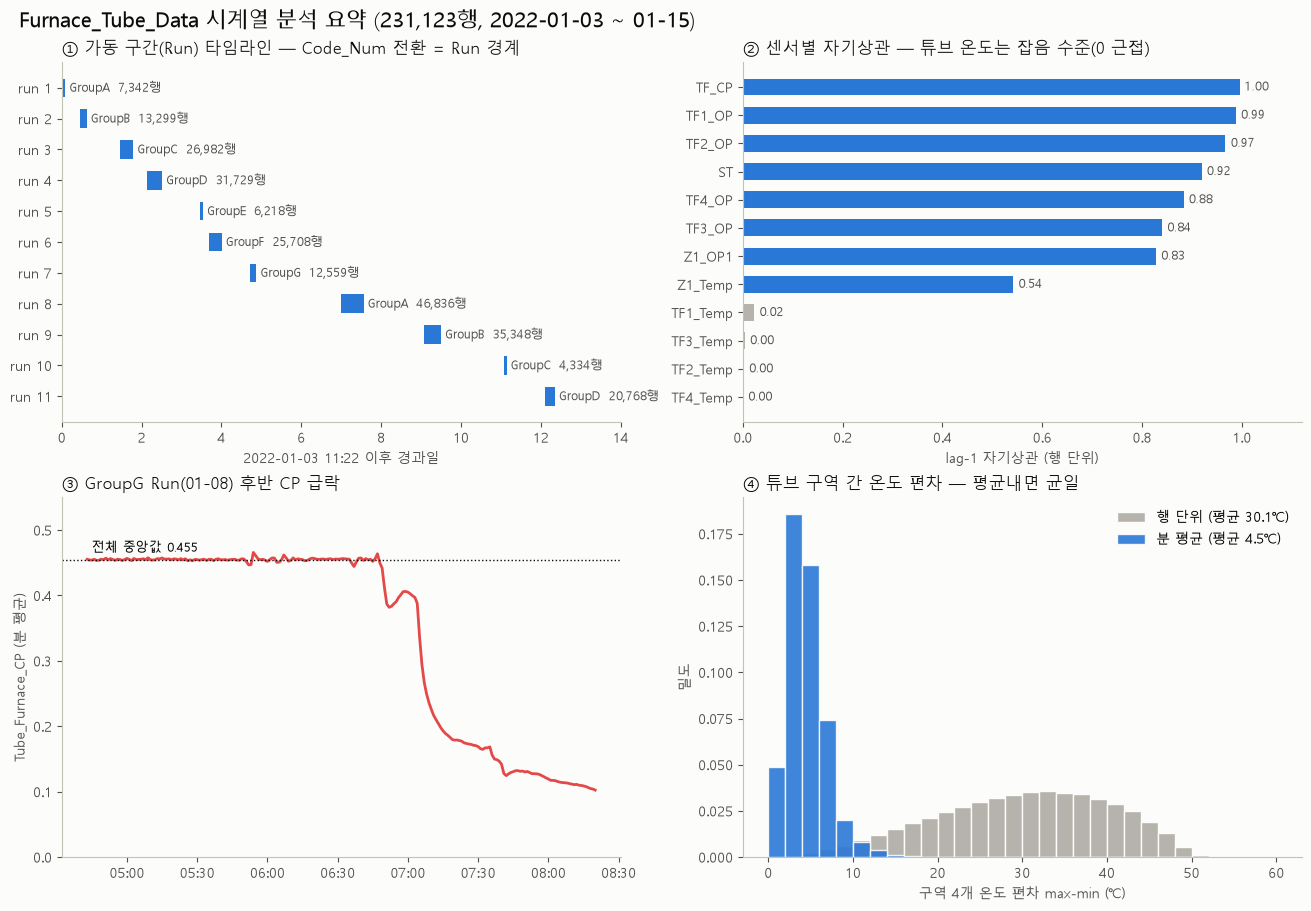

In [15]:
import os
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'font.size': 10,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
BLUE, ORANGE, RED, GRAY, INK = '#2a78d6', '#eb6834', '#e34948', '#b5b3ab', '#0b0b0b'

fig, ax = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle('Furnace_Tube_Data 시계열 분석 요약 (231,123행, 2022-01-03 ~ 01-15)', fontsize=15, color=INK, x=0.01, ha='left')

# ① Run 타임라인
a = ax[0, 0]
for i, (r, row) in enumerate(runs.iterrows()):
    a.barh(i, (row['end'] - row['start']).total_seconds() / 86400 + 1 / 1440,
           left=(row['start'] - runs['start'].min()).total_seconds() / 86400, color=BLUE, height=0.6)
    a.text((row['end'] - runs['start'].min()).total_seconds() / 86400 + 0.1, i,
           f"{row['Code_Num']}  {row['rows']:,}행", va='center', fontsize=8.5, color='#52514e')
a.set_yticks(range(len(runs)), [f'run {r}' for r in runs.index]); a.invert_yaxis()
a.set_xlim(0, 14); a.set_xlabel('2022-01-03 11:22 이후 경과일')
a.set_title('① 가동 구간(Run) 타임라인 — Code_Num 전환 = Run 경계', loc='left', color=INK)

# ② 자기상관
a = ax[0, 1]; s = ac['lag1_row'].sort_values()
a.barh([n.replace('Tube_Furnace', 'TF') for n in s.index], s.values, height=0.6,
       color=[GRAY if v < 0.1 else BLUE for v in s.values])
for i, v in enumerate(s.values):
    a.text(max(v, 0) + 0.01, i, f'{v:.2f}', va='center', fontsize=8.5, color='#52514e')
a.set_xlim(0, 1.12); a.set_xlabel('lag-1 자기상관 (행 단위)')
a.set_title('② 센서별 자기상관 — 튜브 온도는 잡음 수준(0 근접)', loc='left', color=INK)

# ③ GroupG CP 급락
a = ax[1, 0]
a.plot(cp_g.index, cp_g.values, color=RED, lw=2)
a.axhline(df['Tube_Furnace_CP'].median(), color=INK, lw=1, ls=':')
a.text(cp_g.index[2], df['Tube_Furnace_CP'].median() + 0.012, f'전체 중앙값 {df["Tube_Furnace_CP"].median():.3f}', fontsize=9)
a.set_ylabel('Tube_Furnace_CP (분 평균)'); a.set_ylim(0, 0.55)
a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M'))
a.set_title('③ GroupG Run(01-08) 후반 CP 급락', loc='left', color=INK)

# ④ 구역 간 온도 편차
a = ax[1, 1]; bins = np.arange(0, 62, 2)
a.hist(row_range, bins=bins, color=GRAY, edgecolor='#fcfcfb', density=True, label='행 단위 (평균 30.1℃)')
a.hist(min_range, bins=bins, color=BLUE, edgecolor='#fcfcfb', density=True, alpha=0.9, label='분 평균 (평균 4.5℃)')
a.set_xlabel('구역 4개 온도 편차 max-min (℃)'); a.set_ylabel('밀도'); a.legend(frameon=False)
a.set_title('④ 튜브 구역 간 온도 편차 — 평균내면 균일', loc='left', color=INK)

os.makedirs('output', exist_ok=True)
fig.savefig('output/Furnace_Tube_Data_summary.png', dpi=150)
plt.show()

## 결론 요약
- **구조**: 231,123행 × 15열, 2022-01-03 11:22 ~ 01-15 19:49. 타임스탬프는 분 단위이며 분당 ~58행(약 1초 샘플링)
- **Run**: `Code_Num` 전환 지점 = 3.8시간~2일 공백 = 가동 구간 경계 → **11개 Run** (GroupA~D 는 2회, E~G 1회)
- **Process_Type**(OP-A/B/C)은 행 단위로 23,360회 전환 → 배치 구분이 아니라 행 속성
- **신호 특성**: OP·CP·ST·Z1 은 연속 제어 신호(자기상관 0.54~1.00), **튜브 온도 4개는 자기상관 ≈ 0** (885℃ ± 14℃ 잡음 형태)
- **균일성**: 행 단위 구역 편차 평균 30.1℃지만 분 평균 시 4.5℃ → 순간값보다 평균 기반 모니터링 권장
- **이벤트**: GroupG Run(01-08) 07시 이후 **CP 0.45 → 0.11 급락**, Tube_Furnace1_OP 는 약 6% 시간 동안 40 미만(0 근처)으로 떨어짐
- **결측**: 343셀(284행) — Tube_Furnace1_OP 254개가 run 2·10 에 블록으로 몰려 있음